In [2]:

# Step 3.2 - Check PyTorch and Transformers

import torch
import transformers
import accelerate

# 1. Display installed versions
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("Accelerate version:", accelerate.__version__)

# 2. Check whether a GPU is available
print("\nCUDA GPU available:", torch.cuda.is_available())

# 3. Select the training device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

# 4. Display GPU name if available
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected. Training will use the CPU.")

print("\nEnvironment check completed successfully!")


PyTorch version: 2.15.0+cpu
Transformers version: 5.22.2
Accelerate version: 1.15.0

CUDA GPU available: False
Selected device: cpu
No CUDA GPU detected. Training will use the CPU.

Environment check completed successfully!


In [3]:

# Step 3.3 - Load DistilBERT Tokenizer

from transformers import AutoTokenizer

# 1. Select pretrained DistilBERT model
model_name = "distilbert-base-uncased"

# 2. Load pretrained tokenizer
print("Loading DistilBERT tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")

# 3. Example customer review
sample_review = "This product is amazing!"

# 4. Convert review into tokens
tokens = tokenizer.tokenize(sample_review)

print("\nOriginal review:")
print(sample_review)

print("\nTokens:")
print(tokens)

# 5. Convert text into token IDs
encoded = tokenizer(
    sample_review,
    truncation=True,
    padding="max_length",
    max_length=32,
    return_tensors="pt"
)

print("\nInput IDs:")
print(encoded["input_ids"])

print("\nAttention Mask:")
print(encoded["attention_mask"])

# 6. Display tokenizer information
print("\nVocabulary size:", tokenizer.vocab_size)

print("\nTokenization completed successfully!")


Loading DistilBERT tokenizer...
Tokenizer loaded successfully!

Original review:
This product is amazing!

Tokens:
['this', 'product', 'is', 'amazing', '!']

Input IDs:
tensor([[ 101, 2023, 4031, 2003, 6429,  999,  102,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0]])

Attention Mask:
tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0]])

Vocabulary size: 30522

Tokenization completed successfully!


In [4]:

# Step 3.4 - Load and Tokenize Training and Validation Data

import pandas as pd
import torch
from pathlib import Path
from torch.utils.data import Dataset

# 1. Locate the project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Load training and validation data
train_df = pd.read_csv(project_path / "data" / "train.csv")
val_df = pd.read_csv(project_path / "data" / "validation.csv")

print("Training reviews:", len(train_df))
print("Validation reviews:", len(val_df))

# 3. Create a custom PyTorch Dataset
class SentimentDataset(Dataset):

    def __init__(self, texts, labels, tokenizer, max_length=128):
        self.texts = list(texts)
        self.labels = list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = str(self.texts[index])
        label = int(self.labels[index])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(label, dtype=torch.long)
        }

# 4. Create training dataset
train_dataset = SentimentDataset(
    texts=train_df["text"],
    labels=train_df["sentiment"],
    tokenizer=tokenizer,
    max_length=128
)

# 5. Create validation dataset
val_dataset = SentimentDataset(
    texts=val_df["text"],
    labels=val_df["sentiment"],
    tokenizer=tokenizer,
    max_length=128
)

# 6. Check dataset sizes
print("\nTokenized training samples:", len(train_dataset))
print("Tokenized validation samples:", len(val_dataset))

# 7. Inspect the first training sample
sample = train_dataset[0]

print("\nFirst training sample:")
print("Input IDs shape:", sample["input_ids"].shape)
print("Attention Mask shape:", sample["attention_mask"].shape)
print("Sentiment label:", sample["labels"].item())

print("\nDataset preparation completed successfully!")


Training reviews: 3462
Validation reviews: 742

Tokenized training samples: 3462
Tokenized validation samples: 742

First training sample:
Input IDs shape: torch.Size([128])
Attention Mask shape: torch.Size([128])
Sentiment label: 2

Dataset preparation completed successfully!


In [5]:

# Step 3.5 - Load Pretrained DistilBERT Classification Model

import torch
from transformers import AutoModelForSequenceClassification

# 1. Select pretrained model
model_name = "distilbert-base-uncased"

# 2. Define sentiment labels
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

# 3. Load DistilBERT with a 3-class classification head
print("Loading pretrained DistilBERT model...")

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# 4. Move model to the selected device
distilbert_model = distilbert_model.to(device)

# 5. Display model information
print("\nModel loaded successfully!")
print("Model name:", model_name)
print("Number of sentiment classes:", distilbert_model.config.num_labels)
print("Selected device:", device)

# 6. Count model parameters
total_parameters = sum(
    p.numel() for p in distilbert_model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in distilbert_model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

print("\nDistilBERT classification model is ready!")


Loading pretrained DistilBERT model...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Model loaded successfully!
Model name: distilbert-base-uncased
Number of sentiment classes: 3
Selected device: cpu

Total parameters: 66,955,779
Trainable parameters: 66,955,779

DistilBERT classification model is ready!


In [6]:

# Step 3.6 - Fine-tune DistilBERT (Small CPU Test)

import torch
from torch.utils.data import DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm

# 1. Use a small subset for our first training test
small_train_dataset = torch.utils.data.Subset(
    train_dataset,
    range(200)
)

# 2. Create DataLoader
train_loader = DataLoader(
    small_train_dataset,
    batch_size=8,
    shuffle=True
)

# 3. Create optimizer
optimizer = AdamW(
    distilbert_model.parameters(),
    lr=2e-5
)

# 4. Configure training
num_epochs = 1

distilbert_model.train()

print("Starting DistilBERT training on CPU...")

# 5. Training loop
for epoch in range(num_epochs):

    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        # Move inputs to CPU/GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=round(loss.item(), 4)
        )

    average_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch + 1} - "
        f"Average Training Loss: {average_loss:.4f}"
    )

print("\nSmall DistilBERT training experiment completed!")


Starting DistilBERT training on CPU...


Epoch 1/1:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 1 - Average Training Loss: 0.8514

Small DistilBERT training experiment completed!


In [7]:

# Step 3.7 - Estimate Full Training Time

# Enter the time your previous experiment took, in minutes
small_training_minutes = 10  # Replace 10 with your actual time

small_samples = 200
full_samples = len(train_dataset)

# Estimate training time for one epoch
estimated_minutes = (
    small_training_minutes * full_samples / small_samples
)

print("Full training samples:", full_samples)
print("Estimated time for 1 epoch:",
      round(estimated_minutes, 1), "minutes")

print("Estimated time for 2 epochs:",
      round(estimated_minutes * 2, 1), "minutes")


Full training samples: 3462
Estimated time for 1 epoch: 173.1 minutes
Estimated time for 2 epochs: 346.2 minutes


In [8]:

# Step 3.8 - Fine-tune DistilBERT on 1,000 Reviews

import torch
import random
import numpy as np
import time

from pathlib import Path
from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

# 1. Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# 2. Select 1,000 reviews using stratified sampling
subset_indices, _ = train_test_split(
    np.arange(len(train_df)),
    train_size=1000,
    random_state=42,
    stratify=train_df["sentiment"]
)

subset_df = train_df.iloc[subset_indices].copy()

print("Selected training reviews:", len(subset_df))

print("\nSentiment distribution:")
print(subset_df["sentiment"].value_counts().sort_index())

# 3. Create dataset using our existing SentimentDataset class
subset_dataset = SentimentDataset(
    texts=subset_df["text"],
    labels=subset_df["sentiment"],
    tokenizer=tokenizer,
    max_length=128
)

# 4. Create DataLoader
train_loader = DataLoader(
    subset_dataset,
    batch_size=8,
    shuffle=True
)

# 5. Reload original pretrained DistilBERT model
# This avoids continuing from the previous 200-review experiment
print("\nLoading a fresh pretrained DistilBERT model...")

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

distilbert_model.to(device)

# 6. Create optimizer
optimizer = AdamW(
    distilbert_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# 7. Training configuration
num_epochs = 1

print("\nStarting DistilBERT training...")

start_time = time.time()

# 8. Training loop
for epoch in range(num_epochs):

    distilbert_model.train()

    total_loss = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=round(loss.item(), 4)
        )

    average_loss = total_loss / len(train_loader)

    print(
        f"\nEpoch {epoch + 1} "
        f"Average Training Loss: {average_loss:.4f}"
    )

# 9. Calculate training time
elapsed_minutes = (time.time() - start_time) / 60

print("\nTraining time:", round(elapsed_minutes, 2), "minutes")

# 10. Save the fine-tuned model and tokenizer
model_path = project_path / "models" / "distilbert_1000"

model_path.mkdir(parents=True, exist_ok=True)

distilbert_model.save_pretrained(model_path)
tokenizer.save_pretrained(model_path)

print("\nModel saved to:", model_path)

print("\nStep 3.8 completed successfully!")


Selected training reviews: 1000

Sentiment distribution:
sentiment
0    128
1    101
2    771
Name: count, dtype: int64

Loading a fresh pretrained DistilBERT model...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Starting DistilBERT training...


Epoch 1/1:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 1 Average Training Loss: 0.6535

Training time: 15.69 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\distilbert_1000

Step 3.8 completed successfully!


In [9]:

# Step 3.9 - Evaluate Fine-Tuned DistilBERT

import torch
import numpy as np

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Create validation DataLoader
validation_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# 2. Set model to evaluation mode
distilbert_model.eval()

all_predictions = []
all_labels = []

print("Evaluating DistilBERT on validation data...")

# 3. Disable gradient calculations
with torch.no_grad():

    for batch in validation_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Forward pass
        outputs = distilbert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Get predicted sentiment class
        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

# 4. Calculate evaluation metrics
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

# 5. Display results
print("\nDistilBERT Validation Results")
print("----------------------------")

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall: {recall:.4f}")
print(f"Macro F1 Score: {macro_f1:.4f}")

# 6. Detailed classification report
print("\nClassification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

# 7. Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(cm)

print("\nStep 3.9 completed successfully!")


Evaluating DistilBERT on validation data...

DistilBERT Validation Results
----------------------------
Accuracy: 0.8369
Macro Precision: 0.4996
Macro Recall: 0.5369
Macro F1 Score: 0.5171

Classification Report:
              precision    recall  f1-score   support

    Negative       0.63      0.63      0.63        95
     Neutral       0.00      0.00      0.00        74
    Positive       0.87      0.98      0.92       573

    accuracy                           0.84       742
   macro avg       0.50      0.54      0.52       742
weighted avg       0.75      0.84      0.79       742


Confusion Matrix:
[[ 60   0  35]
 [ 23   0  51]
 [ 12   0 561]]

Step 3.9 completed successfully!


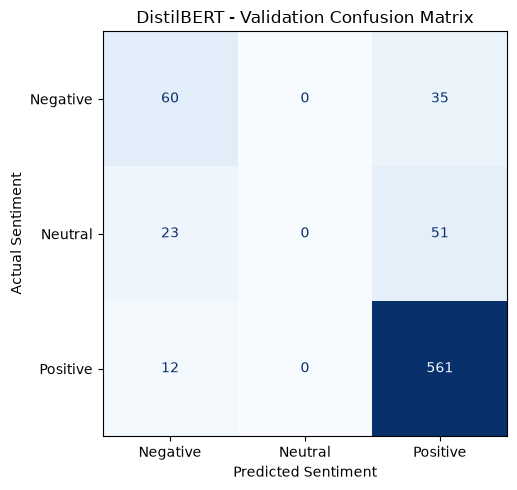

Confusion matrix saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\distilbert_confusion_matrix.png
Step 3.10 completed successfully!


In [10]:

# Step 3.10 - Visualize DistilBERT Confusion Matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Create visualization
fig, ax = plt.subplots(figsize=(7, 5))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("DistilBERT - Validation Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()

# Save figure
figure_path = (
    project_path
    / "data"
    / "distilbert_confusion_matrix.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Confusion matrix saved to:", figure_path)
print("Step 3.10 completed successfully!")


In [11]:

# Step 3.11 - Calculate Class Weights

import numpy as np
import torch

from sklearn.utils.class_weight import compute_class_weight

# 1. Get training labels
train_labels = subset_df["sentiment"].to_numpy()

# 2. Calculate balanced class weights
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_labels
)

# 3. Convert weights to PyTorch tensor
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

# 4. Display class weights
sentiment_names = ["Negative", "Neutral", "Positive"]

print("Calculated Class Weights")
print("------------------------")

for name, weight in zip(sentiment_names, class_weights):
    print(f"{name}: {weight:.4f}")

print("\nClass weights tensor:", class_weights_tensor)

print("\nStep 3.11 completed successfully!")


Calculated Class Weights
------------------------
Negative: 2.6042
Neutral: 3.3003
Positive: 0.4323

Class weights tensor: tensor([2.6042, 3.3003, 0.4323])

Step 3.11 completed successfully!


In [12]:

# Step 3.12 - Train Class-Weighted DistilBERT

import torch
import time
import random
import numpy as np

from transformers import AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from torch.optim import AdamW
from tqdm.auto import tqdm

# 1. Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# 2. Load a FRESH pretrained model
# Keep the original fine-tuned model unchanged
print("Loading fresh DistilBERT model...")

weighted_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

weighted_model = weighted_model.to(device)

# 3. Create training DataLoader
weighted_train_loader = DataLoader(
    subset_dataset,
    batch_size=8,
    shuffle=True
)

# 4. Define weighted loss function
loss_function = torch.nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# 5. Configure optimizer
optimizer = AdamW(
    weighted_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# 6. Training configuration
num_epochs = 1

print("\nStarting class-weighted training...")

start_time = time.time()

# 7. Training loop
for epoch in range(num_epochs):

    weighted_model.train()
    total_loss = 0.0

    progress_bar = tqdm(
        weighted_train_loader,
        desc=f"Weighted Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = weighted_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate class-weighted loss
        loss = loss_function(
            outputs.logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=round(loss.item(), 4)
        )

    average_loss = total_loss / len(weighted_train_loader)

    print(
        f"\nEpoch {epoch + 1} "
        f"Average Weighted Loss: {average_loss:.4f}"
    )

# 8. Calculate training time
elapsed_minutes = (time.time() - start_time) / 60

print(
    "\nTraining time:",
    round(elapsed_minutes, 2),
    "minutes"
)

# 9. Save the weighted model
weighted_model_path = (
    project_path / "models" / "distilbert_weighted_1000"
)

weighted_model_path.mkdir(
    parents=True,
    exist_ok=True
)

weighted_model.save_pretrained(weighted_model_path)
tokenizer.save_pretrained(weighted_model_path)

print("\nWeighted model saved to:", weighted_model_path)

print("\nStep 3.12 completed successfully!")


Loading fresh DistilBERT model...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Starting class-weighted training...


Weighted Epoch 1/1:   0%|          | 0/125 [00:00<?, ?it/s]


Epoch 1 Average Weighted Loss: 0.9835

Training time: 12.26 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Weighted model saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\distilbert_weighted_1000

Step 3.12 completed successfully!


In [13]:

# Step 3.13 - Evaluate Class-Weighted DistilBERT

import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Create validation DataLoader
weighted_val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# 2. Set model to evaluation mode
weighted_model.eval()

weighted_predictions = []
weighted_labels = []

print("Evaluating class-weighted DistilBERT...")

# 3. Generate predictions
with torch.no_grad():
    for batch in weighted_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = weighted_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        weighted_predictions.extend(
            predictions.cpu().numpy()
        )

        weighted_labels.extend(
            labels.cpu().numpy()
        )

# 4. Calculate metrics
weighted_accuracy = accuracy_score(
    weighted_labels, weighted_predictions
)

weighted_precision = precision_score(
    weighted_labels, weighted_predictions,
    average="macro", zero_division=0
)

weighted_recall = recall_score(
    weighted_labels, weighted_predictions,
    average="macro", zero_division=0
)

weighted_f1 = f1_score(
    weighted_labels, weighted_predictions,
    average="macro", zero_division=0
)

# 5. Print results
print("\nClass-Weighted DistilBERT Results")
print("--------------------------------")

print(f"Accuracy: {weighted_accuracy:.4f}")
print(f"Macro Precision: {weighted_precision:.4f}")
print(f"Macro Recall: {weighted_recall:.4f}")
print(f"Macro F1: {weighted_f1:.4f}")

print("\nClassification Report:")

print(classification_report(
    weighted_labels,
    weighted_predictions,
    labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    zero_division=0
))

# 6. Confusion matrix
weighted_cm = confusion_matrix(
    weighted_labels,
    weighted_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(weighted_cm)

print("\nStep 3.13 completed successfully!")


Evaluating class-weighted DistilBERT...

Class-Weighted DistilBERT Results
--------------------------------
Accuracy: 0.5970
Macro Precision: 0.4012
Macro Recall: 0.5299
Macro F1: 0.3801

Classification Report:
              precision    recall  f1-score   support

    Negative       0.25      0.98      0.39        95
     Neutral       0.00      0.00      0.00        74
    Positive       0.96      0.61      0.75       573

    accuracy                           0.60       742
   macro avg       0.40      0.53      0.38       742
weighted avg       0.77      0.60      0.63       742


Confusion Matrix:
[[ 93   0   2]
 [ 60   0  14]
 [223   0 350]]

Step 3.13 completed successfully!


In [14]:

# Step 3.14 - Save DistilBERT Experiment Results

import pandas as pd

experiment_results = pd.DataFrame({
    "Configuration": [
        "Standard DistilBERT",
        "Class-Weighted DistilBERT"
    ],
    "Training Samples": [1000, 1000],
    "Epochs": [1, 1],
    "Accuracy": [0.8369, 0.5970],
    "Macro Precision": [0.4996, 0.4012],
    "Macro Recall": [0.5369, 0.5299],
    "Macro F1": [0.5171, 0.3801],
    "Neutral Recall": [0.0, 0.0]
})

print("DistilBERT Experiment Comparison:")
print(experiment_results.to_string(index=False))

results_path = (
    project_path / "data" / "distilbert_experiments.csv"
)

experiment_results.to_csv(results_path, index=False)

print("\nResults saved to:", results_path)
print("Step 3.14 completed successfully!")


DistilBERT Experiment Comparison:
            Configuration  Training Samples  Epochs  Accuracy  Macro Precision  Macro Recall  Macro F1  Neutral Recall
      Standard DistilBERT              1000       1    0.8369           0.4996        0.5369    0.5171             0.0
Class-Weighted DistilBERT              1000       1    0.5970           0.4012        0.5299    0.3801             0.0

Results saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\distilbert_experiments.csv
Step 3.14 completed successfully!


In [15]:

# Step 3.15 - Fine-tune DistilBERT on Full Training Dataset

import torch
import random
import numpy as np
import time

from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification
from tqdm.auto import tqdm

# 1. Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# 2. Use the complete training dataset
full_train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

print("Total training reviews:", len(train_dataset))
print("Total batches:", len(full_train_loader))

# 3. Load a fresh pretrained DistilBERT model
print("\nLoading fresh pretrained DistilBERT...")

full_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label={
        0: "Negative",
        1: "Neutral",
        2: "Positive"
    },
    label2id={
        "Negative": 0,
        "Neutral": 1,
        "Positive": 2
    }
)

full_model = full_model.to(device)

# 4. Configure optimizer
optimizer = AdamW(
    full_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# 5. Train for one epoch
num_epochs = 1

print("\nStarting full DistilBERT training...")

start_time = time.time()

for epoch in range(num_epochs):

    full_model.train()
    total_loss = 0.0

    progress_bar = tqdm(
        full_train_loader,
        desc=f"Full Training Epoch {epoch + 1}/{num_epochs}"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = full_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=round(loss.item(), 4)
        )

    average_loss = total_loss / len(full_train_loader)

    print(
        f"\nEpoch {epoch + 1} "
        f"Average Training Loss: {average_loss:.4f}"
    )

# 6. Calculate training time
elapsed_minutes = (time.time() - start_time) / 60

print("\nTraining time:", round(elapsed_minutes, 2), "minutes")

# 7. Save full-trained model
full_model_path = (
    project_path / "models" / "distilbert_full"
)

full_model_path.mkdir(
    parents=True,
    exist_ok=True
)

full_model.save_pretrained(full_model_path)
tokenizer.save_pretrained(full_model_path)

print("\nFull model saved to:", full_model_path)

print("\nStep 3.15 completed successfully!")


Total training reviews: 3462
Total batches: 433

Loading fresh pretrained DistilBERT...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Starting full DistilBERT training...


Full Training Epoch 1/1:   0%|          | 0/433 [00:00<?, ?it/s]


Epoch 1 Average Training Loss: 0.5115

Training time: 36.7 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Full model saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\distilbert_full

Step 3.15 completed successfully!


In [16]:

# Step 3.16 - Evaluate Full-Trained DistilBERT

import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Prepare validation data
full_val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# 2. Switch model to evaluation mode
full_model.eval()

full_predictions = []
full_labels = []

print("Evaluating full-trained DistilBERT...")

# 3. Generate predictions
with torch.no_grad():

    for batch in full_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = full_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        full_predictions.extend(
            predictions.cpu().numpy()
        )

        full_labels.extend(
            labels.cpu().numpy()
        )

# 4. Calculate evaluation metrics
full_accuracy = accuracy_score(
    full_labels, full_predictions
)

full_precision = precision_score(
    full_labels,
    full_predictions,
    average="macro",
    zero_division=0
)

full_recall = recall_score(
    full_labels,
    full_predictions,
    average="macro",
    zero_division=0
)

full_f1 = f1_score(
    full_labels,
    full_predictions,
    average="macro",
    zero_division=0
)

# 5. Display results
print("\nFull DistilBERT Validation Results")
print("---------------------------------")

print(f"Accuracy: {full_accuracy:.4f}")
print(f"Macro Precision: {full_precision:.4f}")
print(f"Macro Recall: {full_recall:.4f}")
print(f"Macro F1: {full_f1:.4f}")

# 6. Classification report
print("\nClassification Report:")

print(
    classification_report(
        full_labels,
        full_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

# 7. Confusion matrix
full_cm = confusion_matrix(
    full_labels,
    full_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(full_cm)

print("\nStep 3.16 completed successfully!")


Evaluating full-trained DistilBERT...

Full DistilBERT Validation Results
---------------------------------
Accuracy: 0.8625
Macro Precision: 0.5311
Macro Recall: 0.5948
Macro F1: 0.5611

Classification Report:
              precision    recall  f1-score   support

    Negative       0.70      0.80      0.75        95
     Neutral       0.00      0.00      0.00        74
    Positive       0.89      0.98      0.93       573

    accuracy                           0.86       742
   macro avg       0.53      0.59      0.56       742
weighted avg       0.78      0.86      0.82       742


Confusion Matrix:
[[ 76   0  19]
 [ 23   0  51]
 [  9   0 564]]

Step 3.16 completed successfully!


In [17]:

# Step 3.17 - Continue DistilBERT Training (Epoch 2)

import torch
import random
import numpy as np
import time

from torch.utils.data import DataLoader
from torch.optim import AdamW
from transformers import AutoModelForSequenceClassification
from tqdm.auto import tqdm

# 1. Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# 2. Load the saved one-epoch model
print("Loading saved full-trained DistilBERT...")

epoch2_model = AutoModelForSequenceClassification.from_pretrained(
    project_path / "models" / "distilbert_full"
)

epoch2_model = epoch2_model.to(device)

# 3. Prepare full training dataset
epoch2_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True
)

# 4. Configure optimizer
optimizer = AdamW(
    epoch2_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# 5. Train for one additional epoch
epoch2_model.train()

total_loss = 0.0
start_time = time.time()

print("\nStarting second training epoch...")

progress_bar = tqdm(
    epoch2_loader,
    desc="DistilBERT Epoch 2"
)

for batch in progress_bar:

    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    optimizer.zero_grad()

    outputs = epoch2_model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = outputs.loss

    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    progress_bar.set_postfix(
        loss=round(loss.item(), 4)
    )

# 6. Calculate results
average_loss = total_loss / len(epoch2_loader)
elapsed_minutes = (time.time() - start_time) / 60

print("\nEpoch 2 Average Loss:", round(average_loss, 4))
print("Training time:", round(elapsed_minutes, 2), "minutes")

# 7. Save separately
epoch2_model_path = (
    project_path / "models" / "distilbert_full_epoch2"
)

epoch2_model_path.mkdir(
    parents=True,
    exist_ok=True
)

epoch2_model.save_pretrained(epoch2_model_path)
tokenizer.save_pretrained(epoch2_model_path)

print("\nModel saved to:", epoch2_model_path)

print("\nStep 3.17 completed successfully!")


Loading saved full-trained DistilBERT...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]


Starting second training epoch...


DistilBERT Epoch 2:   0%|          | 0/433 [00:00<?, ?it/s]


Epoch 2 Average Loss: 0.3153
Training time: 35.72 minutes


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved to: c:\Users\jyothi\sentiment-analysis-nlp\models\distilbert_full_epoch2

Step 3.17 completed successfully!


In [18]:

# Step 3.18 - Evaluate DistilBERT After Two Epochs

import torch
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Prepare validation DataLoader
epoch2_val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False
)

# 2. Switch model to evaluation mode
epoch2_model.eval()

epoch2_predictions = []
epoch2_labels = []

print("Evaluating DistilBERT after 2 epochs...")

# 3. Generate predictions
with torch.no_grad():

    for batch in epoch2_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = epoch2_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        epoch2_predictions.extend(
            predictions.cpu().numpy()
        )

        epoch2_labels.extend(
            labels.cpu().numpy()
        )

# 4. Calculate evaluation metrics
epoch2_accuracy = accuracy_score(
    epoch2_labels,
    epoch2_predictions
)

epoch2_precision = precision_score(
    epoch2_labels,
    epoch2_predictions,
    average="macro",
    zero_division=0
)

epoch2_recall = recall_score(
    epoch2_labels,
    epoch2_predictions,
    average="macro",
    zero_division=0
)

epoch2_f1 = f1_score(
    epoch2_labels,
    epoch2_predictions,
    average="macro",
    zero_division=0
)

# 5. Display results
print("\nDistilBERT - Two Epoch Validation Results")
print("----------------------------------------")

print(f"Accuracy: {epoch2_accuracy:.4f}")
print(f"Macro Precision: {epoch2_precision:.4f}")
print(f"Macro Recall: {epoch2_recall:.4f}")
print(f"Macro F1: {epoch2_f1:.4f}")

# 6. Detailed classification report
print("\nClassification Report:")

print(
    classification_report(
        epoch2_labels,
        epoch2_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Negative",
            "Neutral",
            "Positive"
        ],
        zero_division=0
    )
)

# 7. Confusion matrix
epoch2_cm = confusion_matrix(
    epoch2_labels,
    epoch2_predictions,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(epoch2_cm)

print("\nStep 3.18 completed successfully!")


Evaluating DistilBERT after 2 epochs...

DistilBERT - Two Epoch Validation Results
----------------------------------------
Accuracy: 0.8666
Macro Precision: 0.7195
Macro Recall: 0.6349
Macro F1: 0.6556

Classification Report:
              precision    recall  f1-score   support

    Negative       0.76      0.73      0.74        95
     Neutral       0.50      0.20      0.29        74
    Positive       0.90      0.98      0.94       573

    accuracy                           0.87       742
   macro avg       0.72      0.63      0.66       742
weighted avg       0.84      0.87      0.85       742


Confusion Matrix:
[[ 69   7  19]
 [ 16  15  43]
 [  6   8 559]]

Step 3.18 completed successfully!


In [19]:

# Step 3.19 - Save Selected DistilBERT Model Information

import pandas as pd

selected_model_info = pd.DataFrame({
    "Parameter": [
        "Model Architecture",
        "Pretrained Model",
        "Training Samples",
        "Validation Samples",
        "Epochs",
        "Batch Size",
        "Learning Rate",
        "Max Sequence Length",
        "Loss Function",
        "Validation Accuracy",
        "Validation Macro F1",
        "Model Path"
    ],
    "Value": [
        "DistilBERT",
        "distilbert-base-uncased",
        len(train_dataset),
        len(val_dataset),
        2,
        8,
        "2e-5",
        128,
        "CrossEntropyLoss",
        round(epoch2_accuracy, 4),
        round(epoch2_f1, 4),
        str(epoch2_model_path)
    ]
})

print("Selected DistilBERT Configuration")
print("--------------------------------")

print(selected_model_info.to_string(index=False))

# Save configuration
configuration_path = (
    project_path / "data" / "selected_distilbert_model.csv"
)

selected_model_info.to_csv(
    configuration_path,
    index=False
)

print("\nConfiguration saved to:", configuration_path)

print("\nStep 3.19 completed successfully!")


Selected DistilBERT Configuration
--------------------------------
          Parameter                                                                Value
 Model Architecture                                                           DistilBERT
   Pretrained Model                                              distilbert-base-uncased
   Training Samples                                                                 3462
 Validation Samples                                                                  742
             Epochs                                                                    2
         Batch Size                                                                    8
      Learning Rate                                                                 2e-5
Max Sequence Length                                                                  128
      Loss Function                                                     CrossEntropyLoss
Validation Accuracy                        